<h1>Содержание<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Подготовка" data-toc-modified-id="Подготовка-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Подготовка</a></span></li><li><span><a href="#Обучение" data-toc-modified-id="Обучение-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Обучение</a></span></li><li><span><a href="#Тестирование" data-toc-modified-id="Тестирование-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Тестирование</a></span></li><li><span><a href="#Чек-лист-проверки" data-toc-modified-id="Чек-лист-проверки-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Чек-лист проверки</a></span></li></ul></div>

#  Прогнозирование заказов такси

Компания «Чётенькое такси» собрала исторические данные о заказах такси в аэропортах. Чтобы привлекать больше водителей в период пиковой нагрузки, нужно спрогнозировать количество заказов такси на следующий час. Постройте модель для такого предсказания.

Значение метрики *RMSE* на тестовой выборке должно быть не больше 48.

Вам нужно:

1. Загрузить данные и выполнить их ресемплирование по одному часу.
2. Проанализировать данные.
3. Обучить разные модели с различными гиперпараметрами. Сделать тестовую выборку размером 10% от исходных данных.
4. Проверить данные на тестовой выборке и сделать выводы.


Данные лежат в файле `taxi.csv`. Количество заказов находится в столбце `num_orders` (от англ. *number of orders*, «число заказов»).

## Подготовка

Загрузим требуемые библиотеки

In [1]:
!pip install phik -q

In [2]:
!pip install scikit-learn==1.1.3 -q

In [3]:
!pip install shap -q

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import shap

from phik import phik_matrix
from phik.report import plot_correlation_matrix

from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import mean_squared_error,make_scorer

from catboost import CatBoostRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.model_selection import RandomizedSearchCV

In [5]:
RANDOM_STATE = 42
TEST_SIZE = 0.1

Считаем наши данные, заранее сделав наш столбец с датой и временем индексом нашего датафрейма

In [6]:
data = pd.read_csv('/datasets/taxi.csv', index_col=[0], parse_dates=[0])
display(data.head(5))
display(data.describe())
data.info()
print('Количество дубликатов')
display(data.duplicated().sum())

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


,num_orders
count,26496.000000
mean,14.070463
std,9.211330
min,0.000000
25%,8.000000
50%,13.000000
75%,19.000000
max,119.000000


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB
Количество дубликатов


26415

Данные считались корректно, сразу можно сказать, что пропусков нет. Дубликатов же слишком много, оно и не мудрено, всего один столбец, поэтому их мы оставляем

Так как мы предсказываем количество заказов по часам, требуется ресэмплировать данные по интервалу в 1 час

In [7]:
data = data.resample('1H').sum()

In [8]:
display(data.head(5))

,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


In [9]:
decomposed = seasonal_decompose(data['num_orders'])

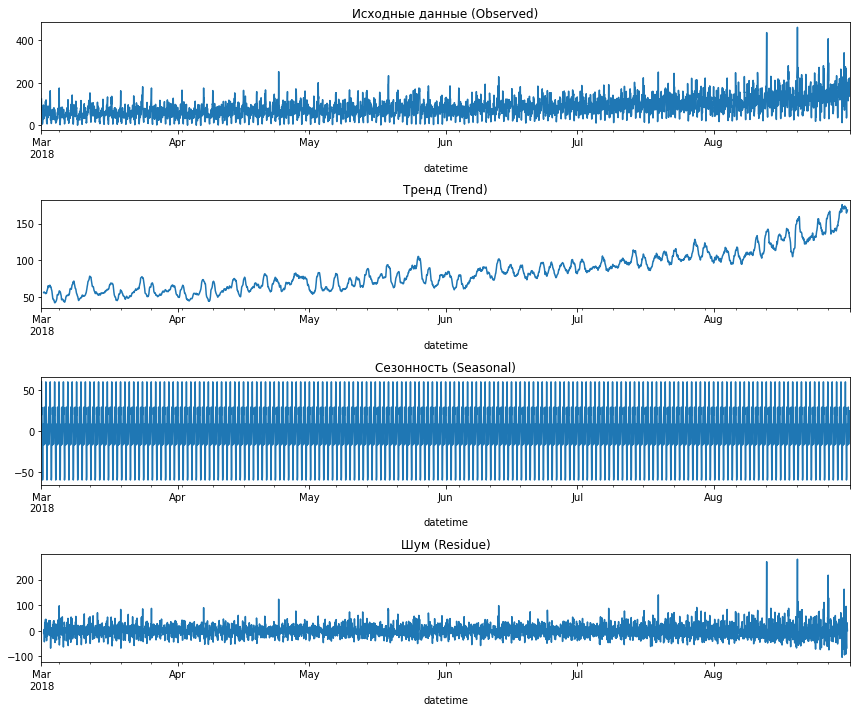

In [10]:
plt.figure(figsize=(12, 10))

plt.subplot(411)
decomposed.observed.plot(ax=plt.gca())
plt.title('Исходные данные (Observed)')

plt.subplot(412)
decomposed.trend.plot(ax=plt.gca())
plt.title('Тренд (Trend)')

plt.subplot(413)
decomposed.seasonal.plot(ax=plt.gca())
plt.title('Сезонность (Seasonal)')

plt.subplot(414)
decomposed.resid.plot(ax=plt.gca())
plt.title('Шум (Residue)')

plt.tight_layout()

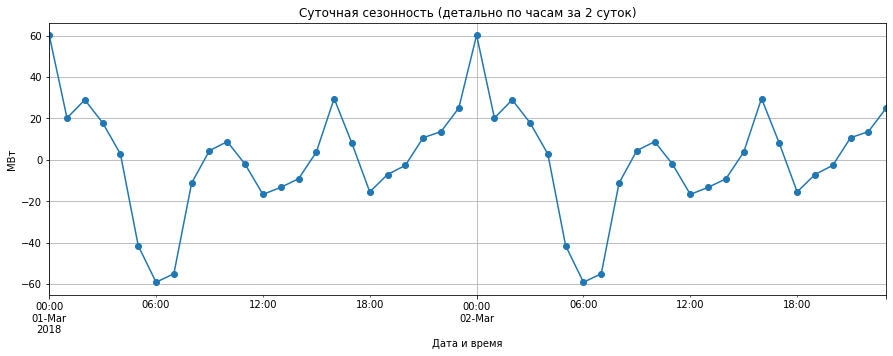

In [11]:
plt.figure(figsize=(15, 5))

decomposed.seasonal.head(48).plot(marker='o')

plt.title('Суточная сезонность (детально по часам за 2 суток)')
plt.xlabel('Дата и время')
plt.ylabel('МВт')
plt.grid(True)
plt.show()

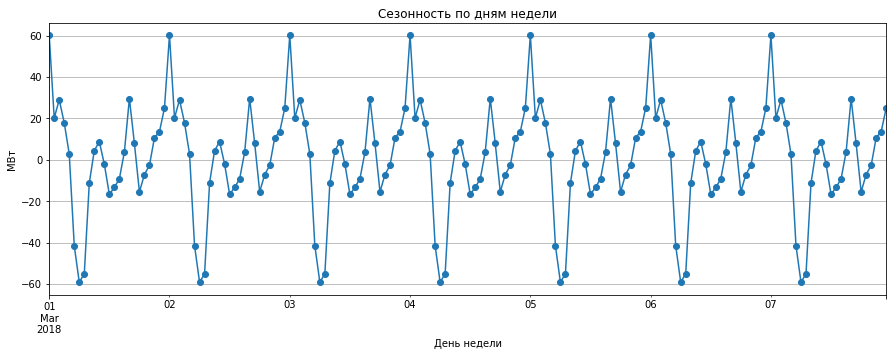

In [12]:
plt.figure(figsize=(15, 5))

decomposed.seasonal.head(168).plot(marker='o')

plt.title('Сезонность по дням недели')
plt.xlabel('День недели')
plt.ylabel('МВт')
plt.grid(True)
plt.show()

На основе построенных графиков можно сказать линия трэнда возрастает по месяцам, значит признак месяца нам нужен. Данные у нас только за один год, значит год нам не нужен. Так же присутствует сезонность по дням недели и времени дня, так что признак часа и дня недели нам понадобятся. Сезонности внутри месяца по дням у нас нет, следовательно день не берем. Отстающие значения всегда хороши, предсказываем будущее на основе прошлого. Скользящее среднее тоже хорошо

Создадим новые признаки всех типов - календарные, отстающих значений и скользящего среднего

In [13]:
def make_features(data, max_lag, rolling_mean_size):
    global lag_cols
    lag_cols = []
    data['hour'] = data.index.hour
    data['month'] = data.index.month
    data['day'] = data.index.day
    data['dayofweek'] = data.index.dayofweek
    
    for lag in range(1, max_lag + 1):
        data['lag_{}'.format(lag)] = data['num_orders'].shift(lag)
        lag_cols.append('lag_{}'.format(lag))

    data['rolling_mean'] = data['num_orders'].shift().rolling(rolling_mean_size).mean()

In [14]:
ML_df = data
make_features(ML_df, 7, 7)

Посмотрим на распределения наших признаков

Построим матрицу корреляций

interval columns not set, guessing: ['num_orders', 'hour', 'month', 'day', 'dayofweek', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'rolling_mean']


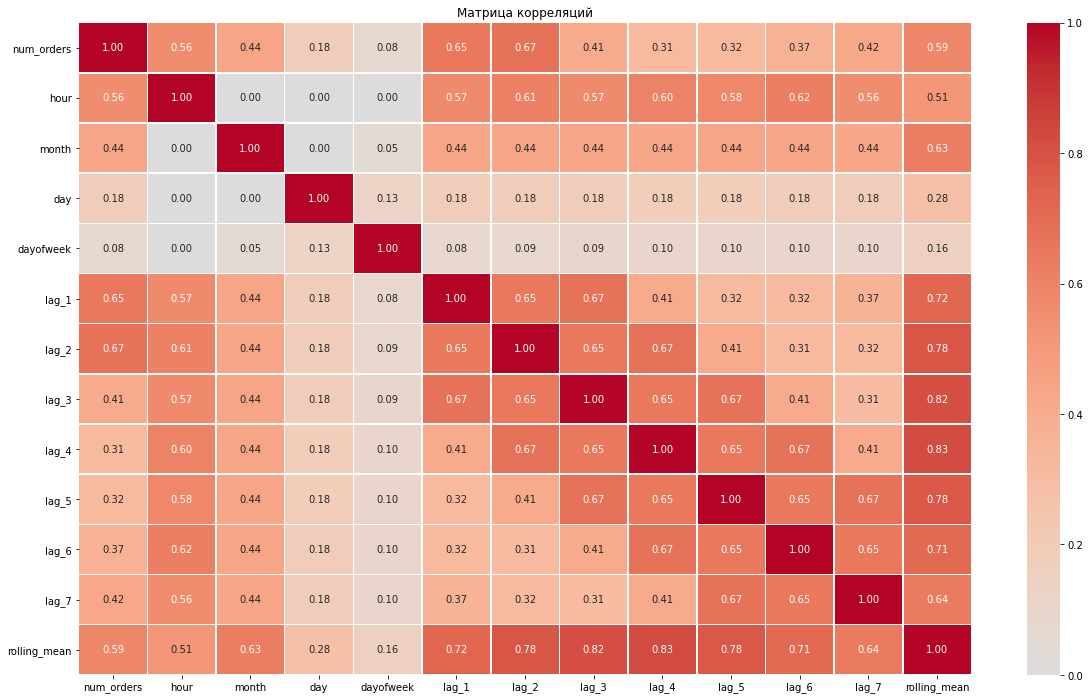

In [15]:
phik_overview = ML_df.phik_matrix()
plt.figure(figsize=(20, 12))
sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
plt.title("Матрица корреляций")
plt.show()

Мультиколлинеарностей не было зафиксировано, как и слишком маленьких значений корреляций, модель обещает быть хорошей

## Обучение

Разделим наши данные на тренировочную и тестовые выборки

In [16]:
X = ML_df.drop('num_orders',axis=1)
y = ML_df['num_orders']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=RANDOM_STATE, test_size=TEST_SIZE, shuffle=False)

Напишем пайплайн для обучения наших моделей

In [22]:
int_cols = ['rolling_mean'] + lag_cols

dis_cols = [
    'hour',
    'month',
    'day',
    'dayofweek'
]

In [23]:
data_preprocessor = ColumnTransformer(
    [('num', StandardScaler(), int_cols + dis_cols)], 
    remainder='passthrough')

In [24]:
pipe_final = Pipeline([
    ('preprocessor', data_preprocessor),
    ('models', DecisionTreeRegressor(random_state=RANDOM_STATE))
])


param_grid = [
    {
        'models': [DecisionTreeRegressor(random_state=RANDOM_STATE)],
        'models__max_depth': range(2,5),
        'models__max_features': range(2,5),
        'preprocessor__num': [StandardScaler(), 'passthrough']  
    },
     
    {
        'models': [CatBoostRegressor(random_state=RANDOM_STATE,early_stopping_rounds=50)],
        'models__iterations': [100, 300, 500],
        'models__learning_rate': [0.01, 0.05, 0.1], 
        'models__depth': [4, 6, 8],
        'preprocessor__num': [StandardScaler(), 'passthrough']   
    },

    {
        'models': [LinearRegression()],
        'preprocessor__num': [StandardScaler(), 'passthrough']  
    }
]

In [25]:
tscv = TimeSeriesSplit(n_splits=5)
r_search = RandomizedSearchCV(
    pipe_final, 
    param_grid, 
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
r_search.fit(X_train, y_train)
print('Лучшая модель')
print()
print(r_search.best_estimator_)
print()
print ('Метрика лучшей модели', r_search.best_score_)
print()
print(r_search.best_params_)

0:	learn: 29.0836277	total: 53.2ms	remaining: 15.9s
1:	learn: 28.4983268	total: 57.4ms	remaining: 8.56s
2:	learn: 27.8213427	total: 61.5ms	remaining: 6.09s
3:	learn: 27.2133209	total: 65.4ms	remaining: 4.84s
4:	learn: 26.6440345	total: 69ms	remaining: 4.07s
5:	learn: 26.1018522	total: 73ms	remaining: 3.58s
6:	learn: 25.5558518	total: 76.7ms	remaining: 3.21s
7:	learn: 25.0588235	total: 80.4ms	remaining: 2.93s
8:	learn: 24.6124860	total: 83.9ms	remaining: 2.71s
9:	learn: 24.1126635	total: 87.8ms	remaining: 2.54s
10:	learn: 23.7277102	total: 91.8ms	remaining: 2.41s
11:	learn: 23.3338646	total: 95.5ms	remaining: 2.29s
12:	learn: 23.0629182	total: 99.3ms	remaining: 2.19s
13:	learn: 22.6878634	total: 103ms	remaining: 2.1s
14:	learn: 22.3997108	total: 107ms	remaining: 2.03s
15:	learn: 22.0691704	total: 110ms	remaining: 1.96s
16:	learn: 21.7323127	total: 114ms	remaining: 1.9s
17:	learn: 21.4193008	total: 118ms	remaining: 1.84s
18:	learn: 21.0764266	total: 121ms	remaining: 1.79s
19:	learn: 20.7

/opt/conda/lib/python3.9/site-packages/sklearn/model_selection/_validation.py:378: FitFailedWarning: 
25 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
20 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.9/site-packages/sklearn/model_selection/_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/conda/lib/python3.9/site-packages/sklearn/pipeline.py", line 382, in fit
    self._final_estimator.fit(Xt, y, **fit_params_last_step)
  File "/opt/conda/lib/python3.9/site-packages/sklearn/tree/_classes.py", line 1342, in fit
    super().fit(
  File "/opt/conda/lib/python3.9/site-packages/sklearn/tree/_c

0:	learn: 37.3351687	total: 1.37ms	remaining: 409ms
1:	learn: 35.7245391	total: 2.94ms	remaining: 437ms
2:	learn: 34.3778689	total: 4.28ms	remaining: 424ms
3:	learn: 33.5033919	total: 5.61ms	remaining: 415ms
4:	learn: 32.5069073	total: 6.82ms	remaining: 402ms
5:	learn: 31.8558656	total: 8.08ms	remaining: 396ms
6:	learn: 31.0062641	total: 9.34ms	remaining: 391ms
7:	learn: 30.1927105	total: 10.6ms	remaining: 387ms
8:	learn: 29.5865848	total: 11.8ms	remaining: 383ms
9:	learn: 29.1724926	total: 13.1ms	remaining: 379ms
10:	learn: 28.8129156	total: 14.3ms	remaining: 375ms
11:	learn: 28.5039072	total: 15.5ms	remaining: 373ms
12:	learn: 28.1324633	total: 16.6ms	remaining: 367ms
13:	learn: 27.7933693	total: 17.9ms	remaining: 365ms
14:	learn: 27.3295384	total: 19.1ms	remaining: 364ms
15:	learn: 27.0313966	total: 20.3ms	remaining: 361ms
16:	learn: 26.7616484	total: 21.6ms	remaining: 360ms
17:	learn: 26.4987375	total: 22.8ms	remaining: 357ms
18:	learn: 26.2048176	total: 24.1ms	remaining: 357ms
19:

Метрика получилась удовлетворительная, лучшей моделью оказался катбуст

## Тестирование

Проверим как наша модель справится с тестовой выборкой

In [26]:
preds = r_search.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test,preds))
print('Метрика на тестовой выборке',rmse_test)

Метрика на тестовой выборке 44.607881600451506


Метрика удовлетворяет требованиям

In [27]:
best_pipeline = r_search.best_estimator_

preprocessor = best_pipeline.named_steps['preprocessor']

catboost_model = best_pipeline.named_steps['models']

In [28]:
X_train_preprocessed = preprocessor.transform(X_train)

X_test_preprocessed = preprocessor.transform(X_test)

feature_names = dis_cols + int_cols

In [29]:
X_train_preprocessed_df = pd.DataFrame(X_train_preprocessed, columns=feature_names)
X_test_preprocessed_df = pd.DataFrame(X_test_preprocessed, columns=feature_names)

In [30]:
explainer = shap.TreeExplainer(catboost_model, data=X_train_preprocessed_df)

shap_values = explainer.shap_values(X_test_preprocessed_df)

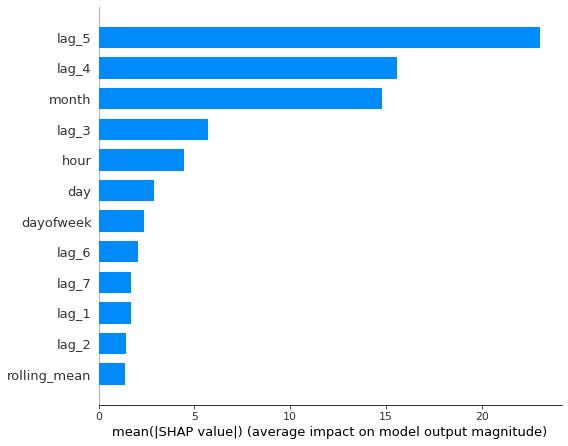

In [31]:
shap.summary_plot(shap_values, X_test_preprocessed_df, plot_type="bar", feature_names=feature_names)

Самой лучшей моделью оказался катбуст со скоростью обучения 0.05, 300 итерациями и глубиной 8, она посчитала, что самые важные признаки это отстающее 4,5 позиции значение таргета и месяц

## Чек-лист проверки

- [x]  Jupyter Notebook открыт
- [x]  Весь код выполняется без ошибок
- [x]  Ячейки с кодом расположены в порядке исполнения
- [x]  Данные загружены и подготовлены
- [x]  Данные проанализированы
- [x]  Модель обучена, гиперпараметры подобраны
- [x]  Качество моделей проверено, выводы сделаны
- [x]  Значение *RMSE* на тестовой выборке не больше 48